![Banner](../../../../Images/Banner/07_remote_sensing/09_11_banner_rs_foundation_models.png)

# Foundation Model Embeddings as Covariates: Digital Soil Mapping of SOC

Digital soil mapping predicts a soil property everywhere from samples at a few places and covariates
known everywhere: terrain, climate, vegetation, parent material. Choosing and preparing those
covariates is most of the work. Foundation model embeddings offer a different kind of covariate:
learned summaries of what the land surface looks like and how it behaves through the year. This
notebook maps topsoil organic carbon (SOC) across the US Great Plains from 570 samples with three
sets of covariates (classical, AlphaEarth embeddings, and both), compares them with spatial
cross-validation, asks what the embedding dimensions represent, checks the residuals with a
variogram, and maps SOC with its area of applicability.

## Overview

### Covariates in digital soil mapping

The **scorpan** model (McBratney et al. 2003) predicts a soil property from **s**oil (other
properties), **c**limate, **o**rganisms (vegetation, land use), **r**elief, **p**arent material,
**a**ge and **n** (space). Classical covariates are raster layers that stand for each factor:
elevation and slope for relief, precipitation and temperature for climate, NDVI and land cover for
organisms, texture for parent material.

### Embeddings as learned covariates

An AlphaEarth embedding summarizes a year of optical, radar, lidar and climate observations at a
pixel. It already contains much of what the classical covariates represent (vegetation, moisture,
terrain texture, land use) and possibly things no single covariate captures. It is also opaque: a
dimension has no name, and its relation to soil is learned only through the model fitted on the
samples.

### Risks

- **Spatial autocorrelation**: nearby samples are similar, so random cross-validation is optimistic;
  folds must be spatial.
- **Dimensionality**: 64 embedding dimensions for 570 samples invites overfitting; regularization,
  PCA or tree ensembles help.
- **Interpretability**: importance can be measured, but a dimension must be related to known
  covariates to be explained.
- **Area of applicability**: predictions far, in covariate space, from every training sample are
  extrapolations. The dissimilarity index of Meyer and Pebesma (2021) marks them.

### Residual structure

If covariates explain the spatial pattern of SOC, the residuals of the model have little spatial
structure left: their variogram is flat (pure nugget). If not, regression kriging can add the
remaining spatial signal.

## Embeddings as Covariates with GeoLattice

| Step | GeoLattice |
|---|---|
| embeddings at the samples | `fm.sample_alphaearth(points, year)` (cached by notebook 09_11_07) |
| embeddings on a map grid | `fm.alphaearth_to_xarray(region, year, scale=, crs=)` (public GeoTIFF overviews at coarse scales) |
| classical covariates | GeoTIFFs sampled with `rasterio` |
| probes and models | `fm.linear_probe` (ridge), scikit-learn random forest with spatial `GroupKFold` |
| variogram | `geolattice.geostatistics.Variogram` |
| area of applicability | `geolattice.rsense.xai.aoa.dissimilarity_index` |

### Learning objectives

1. Assemble classical covariates and AlphaEarth embeddings at soil sampling points.
2. Compare three covariate sets with spatial cross-validation and two model types.
3. Reduce the embedding dimensions with PCA and find how many matter.
4. Relate important embedding dimensions to classical covariates.
5. Check whether the residuals keep spatial structure.
6. Map SOC with the best model and mark where the map is an extrapolation.

### Data

| Dataset | Content |
|---|---|
| Great Plains SOC | 570 topsoil SOC samples (kg m-2), USA Contiguous Albers |
| Classical covariates | 90 m rasters: elevation, slope, slope length, aspect, curvature, topographic position, NDVI, land cover, precipitation, temperature, rock fragments, silt and clay, K-factor |
| AlphaEarth | 2020 embeddings at the samples (from notebook 09_11_07) and on a 2 km grid |

### Contents

- Setup
- Samples and covariates
- Three covariate sets under spatial cross-validation
- How many embedding dimensions matter?
- What the embeddings stand for
- Spatial structure of the residuals
- A SOC map and its area of applicability
- Summary and exercises

## Setup

This notebook reads the AlphaEarth table cached by notebook 09_11_07 (run that first). The SOC map also reads AlphaEarth on a 2 km grid once from the public GeoTIFF overviews (no account), then caches it in `outputs/`.

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

import os  # environment variables
import geopandas as gpd  # samples
import rasterio  # covariate sampling
from sklearn.decomposition import PCA  # dimension reduction
from sklearn.ensemble import RandomForestRegressor  # model
from sklearn.inspection import permutation_importance  # importance
from sklearn.linear_model import RidgeCV  # linear model
from sklearn.model_selection import GroupKFold, cross_val_predict  # spatial folds
from sklearn.pipeline import make_pipeline  # scaling + model
from sklearn.preprocessing import StandardScaler  # scaling
SHARED = DATA.parent / "00_shared" / "data_geostatistics" / "Data_GP"  # Great Plains samples
RAST = DATA.parent / "03_spatial_analysis" / "Great_plain" / "Raster"  # covariate rasters
GRID = DATA.parent / "03_spatial_analysis" / "Great_plain" / "gp_grid_new.csv"  # prediction grid with covariates
COVS = ["elev", "slope", "slopeleng", "aspect", "h_curvature", "topo_2000", "ndvi", "nlcd", "preci", "temp",
        "frg", "silt_clay", "kfactor"]  # classical covariate rasters

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## Samples and covariates

The soil samples, the covariate rasters at their locations, and the 64 AlphaEarth values of 2020 at
each sample are joined into one table. The covariate rasters share the samples' Albers projection.

In [2]:
soil = gpd.read_file(SHARED / "GP_POINT_SOC.shp")  # 570 samples
xy = np.c_[soil.geometry.x, soil.geometry.y]  # coordinates (m)
for c in COVS:  # every covariate
    with rasterio.open(RAST / f"{c}.tif") as src:  # the raster
        v = np.array([s[0] for s in src.sample(xy)], dtype="float64")  # value at each sample
        soil[c] = np.where(v == src.nodata, np.nan, v)  # no data -> NaN
ae = pd.read_csv(OUT / "gp_soc_alphaearth_2020.csv")  # cached by notebook 09_11_07
tab = soil.drop(columns="geometry").merge(ae[["SiteID"] + fm.ALPHAEARTH_BANDS], on="SiteID")  # one table
tab = tab.dropna(subset=COVS + fm.ALPHAEARTH_BANDS)  # complete rows only
tab["logSOC"] = np.log1p(tab["SOC"])  # SOC is skewed: model log(1 + SOC)
xy = tab[["SiteID"]].merge(soil.assign(x=soil.geometry.x, y=soil.geometry.y)[["SiteID", "x", "y"]])[["x", "y"]].to_numpy()  # coordinates
groups = pd.qcut(xy[:, 0], 5, labels=False) * 5 + pd.qcut(xy[:, 1], 5, labels=False)  # 5 x 5 spatial blocks
print(len(tab), "samples |", len(COVS), "classical covariates | 64 embedding dimensions | blocks:", len(np.unique(groups)))  # summary
tab[["SOC"] + COVS[:6]].describe().round(2)

560 samples | 13 classical covariates | 64 embedding dimensions | blocks: 23


,SOC,elev,slope,slopeleng,aspect,h_curvature,topo_2000
count,560.00,560.00,560.00,560.00,560.00,560.00,560.00
mean,6.15,1607.42,3.67,3.48,174.62,-0.00,2.06
std,5.03,729.43,4.79,10.33,102.09,0.07,0.81
min,0.15,248.00,0.00,0.00,-1.00,-0.55,1.00
25%,2.51,1133.00,0.95,0.00,95.37,-0.02,2.00
50%,4.73,1584.00,1.90,0.14,180.00,-0.00,2.00
75%,8.78,2201.00,4.52,2.34,270.00,0.02,2.00
max,30.47,3346.00,44.67,109.09,356.31,0.33,4.00


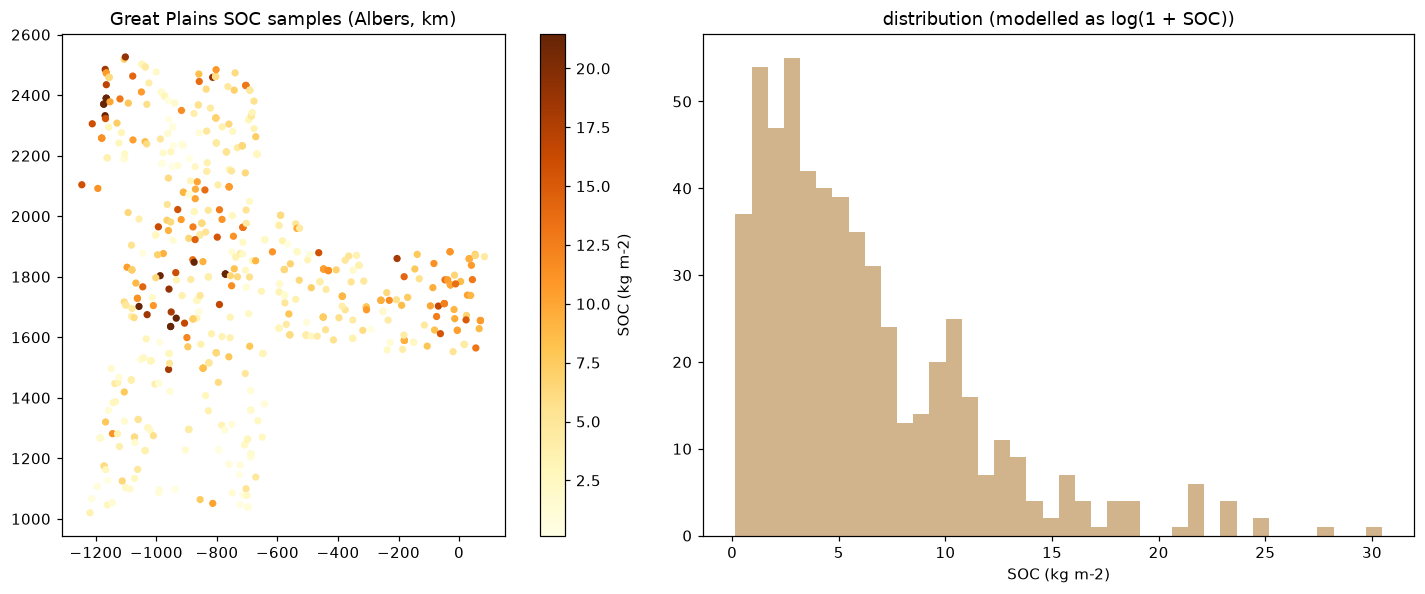

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))  # samples and distribution
sc = ax[0].scatter(xy[:, 0] / 1000, xy[:, 1] / 1000, c=tab["SOC"], cmap="YlOrBr", s=14, vmax=np.percentile(tab["SOC"], 98))  # map
plt.colorbar(sc, ax=ax[0], label="SOC (kg m-2)"); ax[0].set_aspect("equal"); ax[0].set_title("Great Plains SOC samples (Albers, km)")  # labels
ax[1].hist(tab["SOC"], 40, color="tan"); ax[1].set_xlabel("SOC (kg m-2)"); ax[1].set_title("distribution (modelled as log(1 + SOC))")  # histogram
plt.tight_layout(); plt.show()  # draw

## Three covariate sets under spatial cross-validation

Classical covariates, AlphaEarth embeddings, and both together; each with a ridge regression and a
random forest, scored with 5-fold cross-validation over spatial blocks (whole blocks are held out).
Scores are on log(1 + SOC).

In [4]:
SETS = {"classical (13)": COVS, "AlphaEarth (64)": fm.ALPHAEARTH_BANDS, "both (77)": COVS + fm.ALPHAEARTH_BANDS}  # covariate sets
y = tab["logSOC"].to_numpy()  # target
cv = GroupKFold(5)  # spatial folds
rf = lambda: RandomForestRegressor(500, min_samples_leaf=3, max_features=0.33, n_jobs=-1, random_state=SEED)  # random forest
rows, oof = [], {}  # scores and out-of-fold predictions
for name, cols in SETS.items():  # every set
    X = tab[cols].to_numpy()  # features
    r = fm.linear_probe(X, y, task="regression", cv=5, groups=groups, alpha=10.0)  # ridge with spatial folds
    p = cross_val_predict(rf(), X, y, groups=groups, cv=cv)  # random forest, out of fold
    oof[name] = p  # keep for residuals
    rows.append({"covariates": name, "ridge R2": r["mean"]["r2"], "random forest R2": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2),
                 "random forest RMSE": float(np.sqrt(np.mean((y - p) ** 2)))})  # scores
res = pd.DataFrame(rows).set_index("covariates")  # table
res.round(3)

,ridge R2,random forest R2,random forest RMSE
covariates,,,
classical (13),0.431,0.459,0.509
AlphaEarth (64),0.312,0.413,0.530
both (77),0.395,0.444,0.516


The classical covariates predict log SOC best (random forest R2 about 0.46), AlphaEarth alone reaches
about 0.41, and the two together do not improve on the classical set (0.44). The ridge regression
ranks them the same way, lower. With 560 samples over the whole Great Plains, the 13 classical
covariates already hold the main drivers of topsoil carbon (vegetation and climate); the embeddings
carry much of the same information (see below) plus 64 dimensions' worth of noise for the model to
sort through. Embeddings are not a substitute for well-chosen covariates; they are another set to test.

## How many embedding dimensions matter?

The 64 AlphaEarth dimensions are reduced with principal component analysis, fitted inside each training
fold, and a random forest uses the first k components.

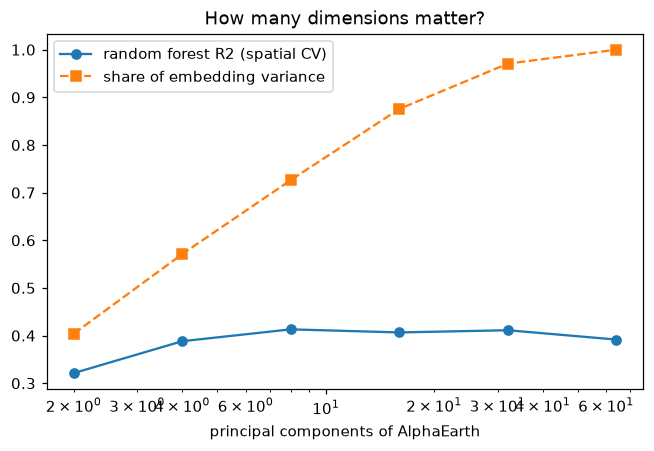

,R2
components,
2,0.321
4,0.388
8,0.413
16,0.407
32,0.411
64,0.392


In [5]:
from sklearn.base import clone  # fresh models per fold

rows = []  # R2 by number of components
E = tab[fm.ALPHAEARTH_BANDS].to_numpy()  # embeddings
for k in [2, 4, 8, 16, 32, 64]:  # components kept
    pred = np.zeros_like(y)  # out-of-fold predictions
    for tr, te in cv.split(E, y, groups):  # spatial folds
        pca = PCA(k, random_state=SEED).fit(E[tr])  # fitted on training folds only
        m = rf().fit(pca.transform(E[tr]), y[tr]); pred[te] = m.predict(pca.transform(E[te]))  # train and predict
    rows.append({"components": k, "R2": 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)})  # score
pcs = pd.DataFrame(rows).set_index("components")  # table
ev = PCA().fit(E).explained_variance_ratio_.cumsum()  # variance explained
ax = pcs["R2"].plot(marker="o", logx=True, figsize=(7, 4.2), label="random forest R2 (spatial CV)")  # curve
ax.plot([2, 4, 8, 16, 32, 64], ev[[1, 3, 7, 15, 31, 63]], "s--", label="share of embedding variance"); ax.legend()  # variance
ax.set_xlabel("principal components of AlphaEarth"); ax.set_title("How many dimensions matter?"); plt.show()  # draw
pcs.round(3)

Eight principal components give almost all of the embeddings' predictive power (R2 about 0.41), and
adding more does not help: with 64 components the score even drops slightly. For small soil data sets
a handful of components is enough, and fewer dimensions make the model easier to fit and to explain.

## What the embeddings stand for

Permutation importance of the random forest on both sets (fitted on all samples) ranks the
covariates and dimensions; each important dimension is then correlated with the classical covariates
to see what it tracks.

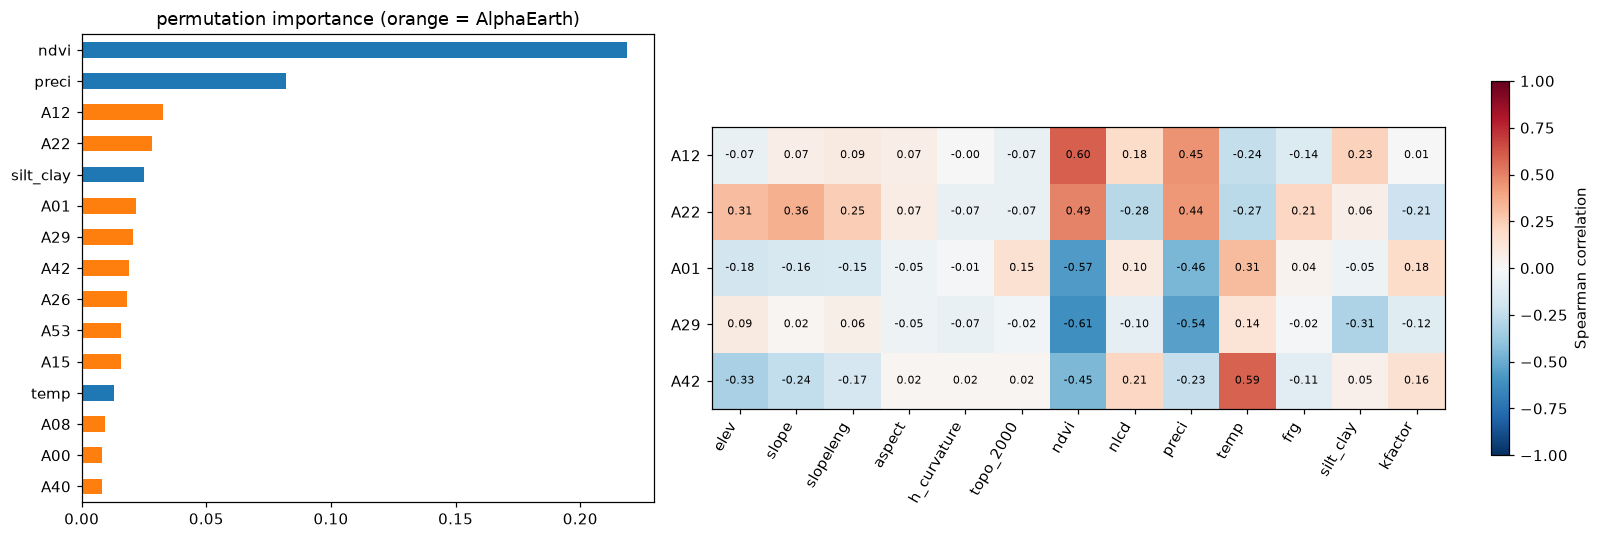

In [6]:
both = SETS["both (77)"]; Xb = tab[both].to_numpy()  # both sets
model = rf().fit(Xb, y)  # random forest on all samples
imp = permutation_importance(model, Xb, y, n_repeats=10, random_state=SEED, n_jobs=-1)  # permutation importance
ranked = pd.Series(imp.importances_mean, index=both).sort_values(ascending=False)  # ranked
top_dims = [c for c in ranked.index if c.startswith("A")][:5]  # five most important embedding dimensions
corr = tab[top_dims + COVS].corr(method="spearman").loc[top_dims, COVS]  # rank correlations with classical covariates
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})  # importance and correlations
ranked.head(15)[::-1].plot.barh(ax=ax[0], color=["tab:orange" if c.startswith("A") else "tab:blue" for c in ranked.head(15).index[::-1]])  # top 15
ax[0].set_title("permutation importance (orange = AlphaEarth)")  # title
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax[1].set_xticks(range(len(COVS)), COVS, rotation=60, ha="right")  # heat map
ax[1].set_yticks(range(len(top_dims)), top_dims); plt.colorbar(im, ax=ax[1], shrink=0.8, label="Spearman correlation")  # labels
for (i, j), v in np.ndenumerate(corr.values):  # values
    ax[1].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)  # write
plt.tight_layout(); plt.show()  # draw

NDVI and precipitation are by far the most important covariates, followed by a group of AlphaEarth
dimensions and silt and clay. The important dimensions are not mysterious: A12 and A22 rise with NDVI
and precipitation (Spearman correlations of about 0.45 to 0.60), A01 and A29 fall with them, and A42
follows temperature. They are learned versions of the vegetation and climate gradient that already
drives the model, which explains why adding them to the classical covariates adds little here.

## Spatial structure of the residuals

The variogram of log SOC and of the out-of-fold residuals of each random forest, with the same lags.
A residual variogram that is flat at the level of its nugget means the covariates captured the spatial
pattern; one that still rises with distance leaves structure for regression kriging.

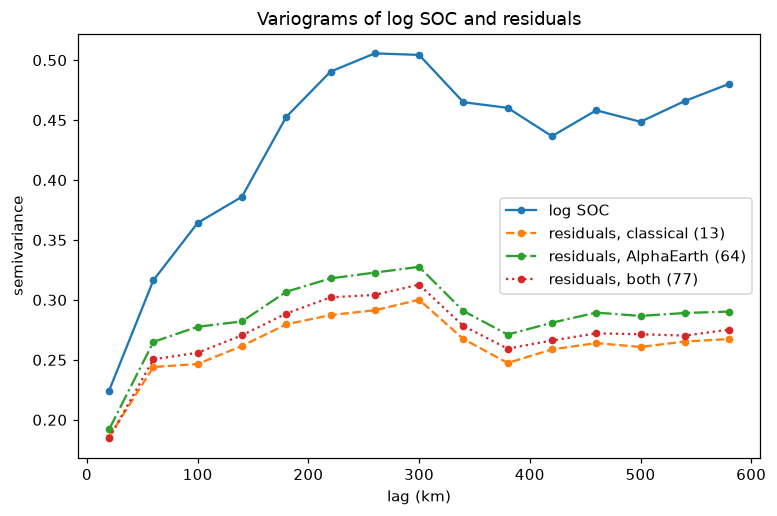

,nugget,partial sill,range (m)
log SOC,0.229288,0.247591,300000.0
"residuals, classical (13)",0.207536,0.066804,300000.0
"residuals, AlphaEarth (64)",0.221893,0.078884,300000.0
"residuals, both (77)",0.209734,0.075114,300000.0


In [7]:
from geolattice.geostatistics import Variogram  # experimental and model variograms

fig, ax = plt.subplots(figsize=(8, 5))  # one panel
series = {"log SOC": y} | {f"residuals, {k}": y - p for k, p in oof.items()}  # target and residuals
fits = {}  # fitted parameters
for (name, z), st in zip(series.items(), ["-", "--", "-.", ":"]):  # every series
    v = Variogram(xy, z, model="spherical", n_lags=15, maxlag=600_000).fit()  # variogram up to 600 km
    lags, gam = np.asarray(v.lags) / 1000, np.asarray(v.experimental)  # lags (km) and semivariance
    ax.plot(lags, gam, "o" + st, ms=4, label=name)  # experimental variogram
    fits[name] = v.fitted_params  # fitted model
ax.set_xlabel("lag (km)"); ax.set_ylabel("semivariance"); ax.legend(); ax.set_title("Variograms of log SOC and residuals"); plt.show()  # draw
pd.DataFrame(fits, index=["nugget", "partial sill", "range (m)"]).T  # fitted spherical model of each series

Log SOC is strongly spatially structured: its semivariance more than doubles from the shortest lags to
about 300 km. All three models remove much of that structure; the residual variograms are lower and
flatter. The classical covariates leave the least structure, AlphaEarth the most, the same order as the
cross-validation scores. Some structure remains at all lags below 300 km, so regression kriging of the
residuals could still add a little (exercise 2). The fitted range in the table sits at 300 km, the
optimizer's starting value, so read the experimental points rather than the fitted range.

## A SOC map and its area of applicability

The prediction grid holds the classical covariates at about one million points. AlphaEarth is read
once on a 2 km grid in the same Albers projection (EPSG:5070) from the overviews of the public GeoTIFFs
(`scale=2000` selects them automatically) and joined to the grid points
by nearest pixel; the random forest trained on both sets predicts log SOC at every point. The
dissimilarity index (DI) measures how far each point is, in weighted covariate space, from the nearest
training sample; points with DI above the threshold learned from the training data are outside the area
of applicability (AOA).

1,009,279 grid points | AOA threshold 0.35 | outside AOA: 2.8%


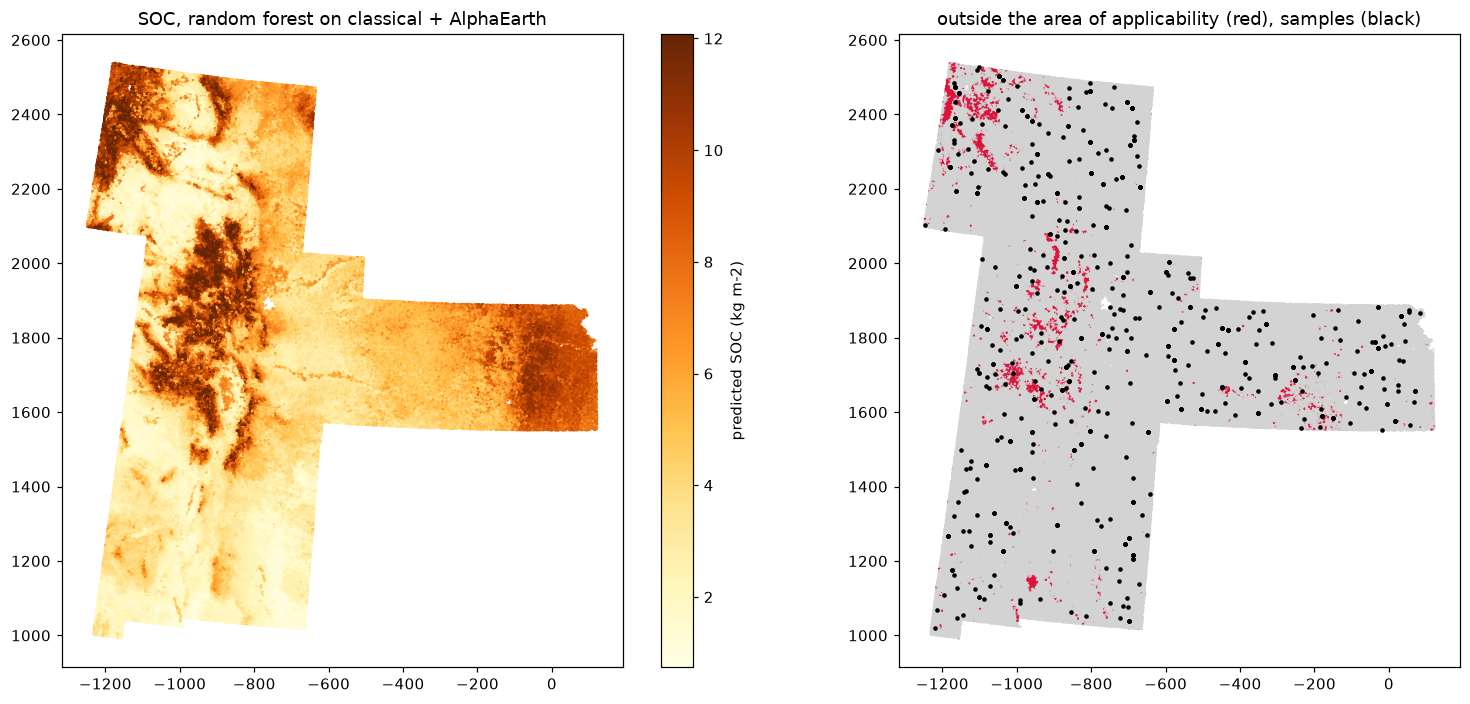

In [8]:
grid = pd.read_csv(GRID)  # covariates on the prediction grid
grid = grid.rename(columns={"slope_g": "slope", "h_curvatur": "h_curvature"})[COVS + ["x", "y"]].dropna()  # same names as the rasters
cache = OUT / "alphaearth_great_plains_2020_2km.nc"  # cached read
if not cache.exists():  # read once from the public GeoTIFF overviews
    region = gpd.GeoDataFrame(geometry=gpd.points_from_xy(grid["x"], grid["y"]), crs=soil.crs).total_bounds  # grid bounds (Albers)
    from shapely.geometry import box  # rectangle
    aoi = gpd.GeoDataFrame(geometry=[box(*region)], crs=soil.crs)  # the area
    t0 = time.perf_counter()  # start the clock
    fm.alphaearth_to_xarray(aoi, 2020, scale=2000, crs="EPSG:5070").drop_vars("spatial_ref", errors="ignore").to_netcdf(cache)  # 2 km grid
    print(f"read in {time.perf_counter() - t0:.0f} s")  # timing
aeg = xr.open_dataarray(cache)  # (64, y, x) at 2 km
gx = xr.DataArray(grid["x"].to_numpy(), dims="p"); gy = xr.DataArray(grid["y"].to_numpy(), dims="p")  # grid points
grid[fm.ALPHAEARTH_BANDS] = aeg.sel(x=gx, y=gy, method="nearest").values.T  # nearest 2 km pixel
grid = grid.dropna()  # points with embeddings
grid["SOC_pred"] = np.expm1(model.predict(grid[both].to_numpy()))  # back-transform to kg m-2
from geolattice.rsense.xai.aoa import dissimilarity_index  # AOA
w = pd.Series(np.clip(imp.importances_mean, 0, None), index=both)  # importance weights
di, thr, _ = dissimilarity_index(tab[both], grid[both].to_numpy(), weights=w.to_numpy(), folds=groups)  # DI and threshold
grid["outside_AOA"] = di > thr  # extrapolation
print(f"{len(grid):,} grid points | AOA threshold {thr:.2f} | outside AOA: {grid['outside_AOA'].mean():.1%}")  # summary
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))  # map and AOA
s = grid.sample(min(len(grid), 300_000), random_state=SEED)  # thin for plotting
im = ax[0].scatter(s["x"] / 1000, s["y"] / 1000, c=s["SOC_pred"], s=0.3, cmap="YlOrBr", vmax=np.percentile(s["SOC_pred"], 98))  # SOC map
plt.colorbar(im, ax=ax[0], label="predicted SOC (kg m-2)"); ax[0].set_title("SOC, random forest on classical + AlphaEarth")  # labels
ax[1].scatter(s["x"] / 1000, s["y"] / 1000, c=np.where(s["outside_AOA"], "crimson", "lightgray"), s=0.3)  # AOA
ax[1].scatter(xy[:, 0] / 1000, xy[:, 1] / 1000, s=4, c="k"); ax[1].set_title("outside the area of applicability (red), samples (black)")  # samples
for a in ax:  # both panels
    a.set_aspect("equal")  # equal axes
plt.tight_layout(); plt.show()  # draw

The map shows the broad patterns of Great Plains topsoil carbon: high values in the Colorado and
Wyoming mountains and in eastern Kansas, low values on the dry plains of eastern Colorado and across
New Mexico. About 3 % of the grid lies outside the area of applicability, mostly in the
northern and central Rocky Mountains, where the combination of covariates and embeddings is unlike any
sample. Those predictions are extrapolations and should be masked or flagged in any product.

## Summary and exercises

### Summary

- AlphaEarth embeddings at soil samples are a ready-made covariate set; classical covariates, the
  embeddings, and both together can be compared directly with spatial cross-validation.
- Spatial folds, random forests or regularized linear models, and PCA keep 64 dimensions from
  overfitting 570 samples.
- Permutation importance and correlations with classical covariates show what the important embedding
  dimensions track.
- The residual variogram shows how much spatial structure the covariates leave, and so whether
  regression kriging is worth adding.
- The area of applicability marks where the map extrapolates beyond the training data.

### Exercises

1. Use AlphaEarth of 2017 instead of 2020 (the earliest year). Do the scores change?
2. Add regression kriging: krige the residuals of the best model with `geolattice.geostatistics.OrdinaryKriging`
   and add them to the random forest map. Does the spatial CV error drop?
3. Replace the 5 x 5 spatial blocks with 10 x 10 blocks and with random folds. How much do the scores change?
4. Average the AlphaEarth embeddings in a 100 m window around each sample instead of taking one 10 m
   pixel (re-normalise the mean vector). Does it help?
5. Predict soil texture (silt and clay) from AlphaEarth alone. Which soil property do the embeddings
   capture best?

### References

- Brown, C. F. et al. (2025). AlphaEarth Foundations. arXiv:2507.22291.
- McBratney, A. B., Mendonca Santos, M. L. and Minasny, B. (2003). On digital soil mapping. Geoderma.
- Meyer, H. and Pebesma, E. (2021). Predicting into unknown space? Estimating the area of applicability of spatial prediction models. Methods in Ecology and Evolution.
- Hengl, T. et al. (2018). Random forest as a generic framework for predictive modeling of spatial and spatio-temporal variables. PeerJ.